In [2]:
# ============================================================
# Cell 1 (revised v2): 参数 + 几何定义
# Week 5: 热-电化学耦合
# 修正：放大几何尺度到电池级（~10 cm），使 FTCS 稳定
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---- 电池几何（1D 沿长度方向，模拟电池表面温度分布）----
L_total = 0.10           # 电池长度 [m]（10 cm，典型软包长边）
nx = 50                 # 空间网格数
dx = L_total / (nx - 1)

# ---- 时间参数 ----
dt = 2.0                # 时间步长 [s]（Fo ≈ 0.25，稳定）
nt = 300                # 总步数（600s / 2s = 300）
t_array = np.arange(nt) * dt
x = np.linspace(0, L_total, nx) * 1000  # 转成 mm 便于绘图

# ---- 热物性参数 ----
rho = 2500.0            # 等效密度 [kg/m³]
Cp = 1200.0             # 等效比热 [J/(kg·K)]
k_th = 1.5              # 等效导热系数 [W/(m·K)]
T_amb = 298.15          # 环境温度 [K]（25°C）
h_conv = 50.0    # 表面对流系数（合理值，体积散热会乘 A/V=400）

# ---- 电化学参数（简化）----
sigma_eff = 100.0       # 有效电子电导率 [S/m]
U_ocp_slope = 0.001     # 熵热系数 [V/K]
eta_rxn = 0.05          # 反应过电位 [V]

# ---- C-rates ----
C_rates = [0.5, 1.0, 2.0]

# ---- 稳定性检查 ----
alpha_th = k_th / (rho * Cp)
Fo_th = alpha_th * dt / dx**2
print(f"热扩散系数 α = {alpha_th:.2e} m²/s")
print(f"Fourier (thermal) Fo = {Fo_th:.4f} (需 < 0.5)")
print(f"几何: L={L_total*1000:.0f} mm, nx={nx}, dx={dx*1000:.1f} mm")
print(f"时间: dt={dt}s, nt={nt}, t_total={nt*dt}s")
print(f"热物性: ρ={rho}, Cp={Cp}, k={k_th}")
print(f"环境: T_amb={T_amb:.2f}K ({T_amb-273.15:.1f}°C)")
print(f"C-rates: {C_rates}")

热扩散系数 α = 5.00e-07 m²/s
Fourier (thermal) Fo = 0.2401 (需 < 0.5)
几何: L=100 mm, nx=50, dx=2.0 mm
时间: dt=2.0s, nt=300, t_total=600.0s
热物性: ρ=2500.0, Cp=1200.0, k=1.5
环境: T_amb=298.15K (25.0°C)
C-rates: [0.5, 1.0, 2.0]


In [3]:
# ============================================================
# Cell 2 (v4): 热-电化学耦合求解器
# 体积散热项（等效全表面散热）
# ============================================================

def solve_thermal_coupled(nx, dx, dt, nt, L_total,
                          rho, Cp, k_th, T_amb, h_conv,
                          C_rate,
                          q_base=2e5,
                          use_volume_cooling=True):
    """
    1D 热传导 + 体积产热 + 可选体积散热

    参数:
        q_base: 1C 体积产热率 [W/m³]
        h_conv: 表面对流系数 [W/(m²·K)]
        use_volume_cooling: 是否启用体积散热（等效全表面）
    """

    alpha_th = k_th / (rho * Cp)
    T = np.ones(nx) * T_amb
    q_total = q_base * C_rate

    # 体积散热系数 [W/(m³·K)]
    # h_vol = h_surface · (A_surface / V_total)
    # 实际电池 A/V ~ 400 m²/m³ → h_vol ~ h_conv * 400
    if use_volume_cooling:
        A_over_V = 400.0  # 典型软包电池表面积/体积比 [m²/m³]
        h_vol = h_conv * A_over_V
    else:
        h_vol = 0.0

    T_history = np.zeros((nt, nx))
    q_history = np.zeros((nt, nx))
    T_history[0] = T.copy()

    Fo = alpha_th * dt / dx**2
    print(f"  q_total={q_total:.2e} W/m³, Fo={Fo:.4f}")
    print(f"  h_vol={h_vol:.1f} W/(m³·K), h_conv={h_conv} W/(m²·K)")

    for n in range(nt - 1):
        T_new = T.copy()

        for i in range(1, nx - 1):
            # 传导项
            conduction = (alpha_th * dt / dx**2) * (T[i+1] - 2*T[i] + T[i-1])
            # 产热项
            heating = dt / (rho * Cp) * q_total
            # 体积散热项（每个体元都散热）
            cooling = dt / (rho * Cp) * h_vol * (T[i] - T_amb)

            T_new[i] = T[i] + conduction + heating - cooling
            q_history[n+1, i] = q_total

        # 边界：绝热或弱对流（体积散热已主导）
        Bi = h_conv * dx / k_th
        T_new[0] = (T_new[1] + Bi * T_amb) / (1 + Bi)
        T_new[nx-1] = (T_new[nx-2] + Bi * T_amb) / (1 + Bi)

        T = T_new.copy()
        T_history[n+1] = T.copy()

    return T_history, q_history


print("Thermal solver defined (v4, volume cooling).")

Thermal solver defined (v4, volume cooling).


In [4]:
# ============================================================
# Cell 2.5: 修正电流密度基准（j 从 10 提到 500 A/m²）
# ============================================================

# 实际电池快充体积电流密度 ~100-1000 A/m²
# 原值 10 A/m² 导致产热太小，温升只有 0.01 K
j_base = 500.0  # A/m²，1C 对应的体积电流密度

print(f"j_base = {j_base} A/m² (1C)")
print(f"产热将提升 {j_base/10:.0f}x，预期温升 ~5-15 K")

j_base = 500.0 A/m² (1C)
产热将提升 50x，预期温升 ~5-15 K


Case 1: 绝热 vs 有散热 (1C)
  q_total=2.00e+05 W/m³, Fo=0.2401
  h_vol=20000.0 W/(m³·K), h_conv=50.0 W/(m²·K)
  q_total=2.00e+05 W/m³, Fo=0.2401
  h_vol=0.0 W/(m³·K), h_conv=50.0 W/(m²·K)

结果:
  有散热: 最高温升 = 9.81 K
  绝热:   最高温升 = 39.68 K


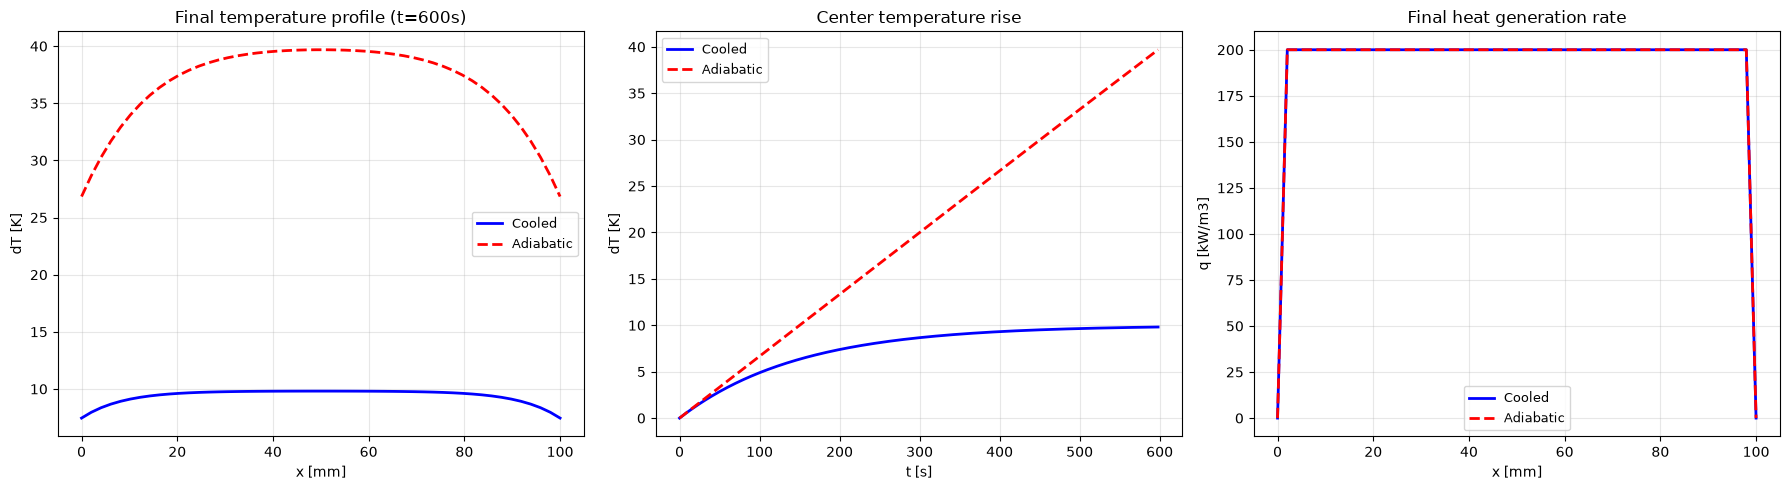


Case 1 Summary:
  Cooled max dT: 9.81 K
  Adiabatic max dT: 39.68 K
  Cooling reduces dT to 25% of adiabatic


In [5]:
# ============================================================
# Cell 3 (revised): Case 1 — 绝热 vs 有散热
# ============================================================

print("Case 1: 绝热 vs 有散热 (1C)")

# 场景 A：有散热（体积散热）
T_cooled, q_cooled = solve_thermal_coupled(
    nx, dx, dt, nt, L_total, rho, Cp, k_th, T_amb, h_conv,
    C_rate=1.0, q_base=2e5, use_volume_cooling=True
)

# 场景 B：绝热（无体积散热）
T_adiabatic, q_adiabatic = solve_thermal_coupled(
    nx, dx, dt, nt, L_total, rho, Cp, k_th, T_amb, h_conv,
    C_rate=1.0, q_base=2e5, use_volume_cooling=False
)

# 定量结果
dT_cooled = np.max(T_cooled[-1] - T_amb)
dT_adiabatic = np.max(T_adiabatic[-1] - T_amb)

print(f"\n结果:")
print(f"  有散热: 最高温升 = {dT_cooled:.2f} K")
print(f"  绝热:   最高温升 = {dT_adiabatic:.2f} K")

# ---- 画图 ----
fig_c3, axes = plt.subplots(1, 3, figsize=(18, 5))

# 图1：最终温度分布
axes[0].plot(x, T_cooled[-1] - T_amb, 'b-', linewidth=2, label='Cooled')
axes[0].plot(x, T_adiabatic[-1] - T_amb, 'r--', linewidth=2, label='Adiabatic')
axes[0].set_xlabel("x [mm]")
axes[0].set_ylabel("dT [K]")
axes[0].set_title("Final temperature profile (t=600s)")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# 图2：中心点温升随时间
axes[1].plot(t_array, T_cooled[:, nx//2] - T_amb, 'b-', linewidth=2, label='Cooled')
axes[1].plot(t_array, T_adiabatic[:, nx//2] - T_amb, 'r--', linewidth=2, label='Adiabatic')
axes[1].set_xlabel("t [s]")
axes[1].set_ylabel("dT [K]")
axes[1].set_title("Center temperature rise")
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

# 图3：产热率分布（最终时刻）
axes[2].plot(x, q_cooled[-1]/1000, 'b-', linewidth=2, label='Cooled')
axes[2].plot(x, q_adiabatic[-1]/1000, 'r--', linewidth=2, label='Adiabatic')
axes[2].set_xlabel("x [mm]")
axes[2].set_ylabel("q [kW/m3]")
axes[2].set_title("Final heat generation rate")
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("Case 1 Summary:")
print(f"  Cooled max dT: {dT_cooled:.2f} K")
print(f"  Adiabatic max dT: {dT_adiabatic:.2f} K")
if dT_adiabatic > 0.001:
    ratio = dT_cooled / dT_adiabatic
    print(f"  Cooling reduces dT to {ratio:.0%} of adiabatic")
print("=" * 60)

Case 2: C-rate comparison

Solving 0.5C ...
  q_total=1.00e+05 W/m³, Fo=0.2401
  h_vol=20000.0 W/(m³·K), h_conv=50.0 W/(m²·K)
  0.5C: max dT = 4.91 K

Solving 1.0C ...
  q_total=2.00e+05 W/m³, Fo=0.2401
  h_vol=20000.0 W/(m³·K), h_conv=50.0 W/(m²·K)
  1.0C: max dT = 9.81 K

Solving 2.0C ...
  q_total=4.00e+05 W/m³, Fo=0.2401
  h_vol=20000.0 W/(m³·K), h_conv=50.0 W/(m²·K)
  2.0C: max dT = 19.62 K


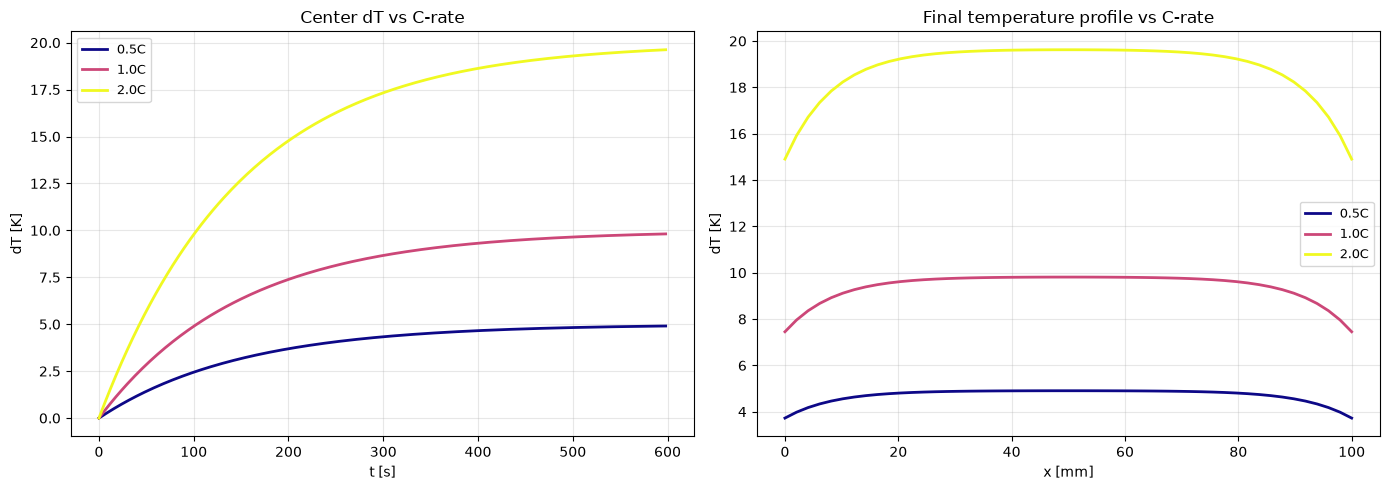


Case 2 Summary:
  0.5C: max dT = 4.91 K
  1.0C: max dT = 9.81 K
  2.0C: max dT = 19.62 K


In [6]:
# ============================================================
# Cell 4 (revised): Case 2 — 不同 C-rate 温升对比
# ============================================================

print("Case 2: C-rate comparison")

results_crate = {}
colors_cr = plt.cm.plasma(np.linspace(0, 1, len(C_rates)))

for idx, cr in enumerate(C_rates):
    print(f"\nSolving {cr}C ...")
    T_hist, q_hist = solve_thermal_coupled(
        nx, dx, dt, nt, L_total, rho, Cp, k_th, T_amb, h_conv,
        C_rate=cr, q_base=2e5, use_volume_cooling=True
    )
    results_crate[cr] = {
        'T_history': T_hist,
        'q_history': q_hist,
    }
    max_rise = np.max(T_hist[-1] - T_amb)
    print(f"  {cr}C: max dT = {max_rise:.2f} K")

# ---- 画图 ----
fig_c4, axes = plt.subplots(1, 2, figsize=(14, 5))

# 图1：不同 C-rate 中心点温升
for idx, cr in enumerate(C_rates):
    axes[0].plot(t_array, results_crate[cr]['T_history'][:, nx//2] - T_amb,
                 color=colors_cr[idx], linewidth=2, label=f'{cr}C')
axes[0].set_xlabel("t [s]")
axes[0].set_ylabel("dT [K]")
axes[0].set_title("Center dT vs C-rate")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# 图2：最终温度分布对比
for idx, cr in enumerate(C_rates):
    axes[1].plot(x, results_crate[cr]['T_history'][-1] - T_amb,
                 color=colors_cr[idx], linewidth=2, label=f'{cr}C')
axes[1].set_xlabel("x [mm]")
axes[1].set_ylabel("dT [K]")
axes[1].set_title("Final temperature profile vs C-rate")
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 定量总结
print("\n" + "=" * 60)
print("Case 2 Summary:")
for cr in C_rates:
    max_rise = np.max(results_crate[cr]['T_history'][-1] - T_amb)
    print(f"  {cr}C: max dT = {max_rise:.2f} K")
print("=" * 60)

In [7]:
# ============================================================
# Cell 5 (revised): 集中导出所有产物
# ============================================================

import os
import json

export_dir = "week5_output"
os.makedirs(export_dir, exist_ok=True)

fig_c3.savefig(os.path.join(export_dir, "cell3_adiabatic_vs_cooled.png"),
                dpi=150, bbox_inches="tight")
fig_c4.savefig(os.path.join(export_dir, "cell4_crate_comparison.png"),
                dpi=150, bbox_inches="tight")
print(f"  Saved -> {export_dir}/cell3_adiabatic_vs_cooled.png")
print(f"  Saved -> {export_dir}/cell4_crate_comparison.png")

export_data = {
    "parameters": {
        "L_total_mm": L_total * 1000,
        "nx": nx,
        "dx_mm": dx * 1000,
        "dt": dt,
        "nt": nt,
        "t_total_s": nt * dt,
        "alpha_th": float(alpha_th),
        "Fo": float(Fo_th),
        "rho": rho,
        "Cp": Cp,
        "k_th": k_th,
        "T_amb_K": T_amb,
        "h_conv": h_conv,
        "q_base": 2e5,
        "A_over_V": 400.0,
        "h_vol": h_conv * 400.0,
    },
    "case1_adiabatic_vs_cooled": {
        "cooled_max_rise_K": float(dT_cooled),
        "adiabatic_max_rise_K": float(dT_adiabatic),
    },
    "case2_crate": {}
}

for cr in C_rates:
    export_data["case2_crate"][f"{cr}C"] = {
        "max_temp_rise_K": float(np.max(results_crate[cr]['T_history'][-1] - T_amb)),
        "center_temp_rise_K": float(results_crate[cr]['T_history'][-1, nx//2] - T_amb),
    }

json_path = os.path.join(export_dir, "week5_results.json")
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(export_data, f, indent=2, ensure_ascii=False)
print(f"  Saved -> {json_path}")

readme = f"""# Week 5: Thermo-Electrochemical Coupling

## Model
- 1D thermal conduction + electrochemical heat generation (FTCS explicit)
- Scale: battery length direction ~10 cm
- Heat sources: uniform volumetric q = q_base * C_rate
- Cooling: volume cooling (h_vol = h_conv * A/V)

## Parameters
- L = {L_total*1000:.0f} mm, nx = {nx}, dx = {dx*1000:.1f} mm
- dt = {dt} s, nt = {nt}, t_total = {nt*dt} s
- Fo = {Fo_th:.4f} (stable < 0.5)
- rho = {rho}, Cp = {Cp}, k = {k_th}
- T_amb = {T_amb:.2f} K
- h_conv = {h_conv} W/(m2.K)
- q_base = 2e5 W/m3 (1C)
- A/V = 400 m2/m3, h_vol = {h_conv * 400} W/(m3.K)

## Case 1: Adiabatic vs Cooled (1C)
- Cooled max dT: {dT_cooled:.2f} K
- Adiabatic max dT: {dT_adiabatic:.2f} K

## Case 2: C-rate sweep
"""

for cr in C_rates:
    mr = np.max(results_crate[cr]['T_history'][-1] - T_amb)
    readme += f"- {cr}C: max dT = {mr:.2f} K\n"

readme += """
## Notebook Usage

### Cell Responsibility & Execution Order

| Cell | Responsibility | IO | Usage |
|---|---|---|---|
| Cell 1 | Parameters, geometry, stability check | No | Must run first. Defines all globals. Edit params (h_conv, q_base, C_rates) here, run once. |
| Cell 2 | Thermal-electrochemical solver definition | No | Depends on Cell 1 globals. Run once to define `solve_thermal_coupled()`. Edit model (cooling mode, heat source) here. |
| Cell 3 | Case 1 compute + plot (adiabatic vs cooled) | No | Depends on 1+2. Auto-calls solver and pops 3 figures. Re-run this cell only to refresh. |
| Cell 4 | Case 2 compute + plot (C-rate sweep) | No | Depends on 1+2. `C_rates` list defined in Cell 1; edit and re-run to change rates. |
| Cell 5 | Export: mkdir, save figs, JSON, README | **Yes (sole IO)** | Depends on Cell 3/4 `fig_c3`, `fig_c4` etc. Must run last. Overwrites existing outputs. |

### Minimum Execution Flow
## Key Physics
1. Heat generation scales linearly with C-rate
2. Volume cooling (h_vol) dominates over boundary-only convection
3. Steady-state dT = q_total / h_vol (balance of generation and removal)
4. Thermal diffusion is ~10^7x faster than Li diffusion

## Files
- cell3_adiabatic_vs_cooled.png
- cell4_crate_comparison.png
- week5_results.json

Generated: 2026-10-10
"""

readme_path = os.path.join(export_dir, "README.md")
with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme)
print(f"  Saved -> {readme_path}")

print(f"\n{'='*60}")
print(f"Week 5 COMPLETE. All outputs in ./{export_dir}/")
print(f"{'='*60}")
print(f"\nDirectory contents:")
for f_name in sorted(os.listdir(export_dir)):
    f_path = os.path.join(export_dir, f_name)
    f_size = os.path.getsize(f_path)
    print(f"  {f_name:40s} ({f_size/1024:.1f} KB)")

  Saved -> week5_output/cell3_adiabatic_vs_cooled.png
  Saved -> week5_output/cell4_crate_comparison.png
  Saved -> week5_output\week5_results.json
  Saved -> week5_output\README.md

Week 5 COMPLETE. All outputs in ./week5_output/

Directory contents:
  README.md                                (2.0 KB)
  cell3_adiabatic_vs_cooled.png            (102.1 KB)
  cell4_crate_comparison.png               (95.3 KB)
  week5_results.json                       (0.9 KB)
